In [8]:
import sys
print(sys.executable)

c:\Users\Saada\python_uv_workspace\.venv\Scripts\python.exe


In [10]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma

from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_google_genai import ChatGoogleGenerativeAI
from IPython.display import Markdown
import os

C:\Users\Saada\AppData\Local\Temp\ipykernel_21400\2331302777.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFDirectoryLoader


In [23]:
# Creating PDF loader object
loader = PyPDFDirectoryLoader(path="r C:/Users/Saada/OneDrive/Escritorio/M2AIDC/ApplicationsDistribuer/TP-AIGENERATIVE/chapitre_1.pdf")

In [22]:
from langchain_community.document_loaders import PyPDFLoader

pdf_path = r"C:\Users\Saada\OneDrive\Escritorio\M2AIDC\ApplicationsDistribuer\TP-AIGENERATIVE\chapitre_1.pdf"

loader = PyPDFLoader(pdf_path)
documents = loader.load()

print("Nombre de pages :", len(documents))

Nombre de pages : 42


In [30]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200
)

ai_initiative_chunks = text_splitter.split_documents(documents)

print("Nombre de pages :", len(documents))
print("Nombre de chunks :", len(ai_initiative_chunks))

Nombre de pages : 42
Nombre de chunks : 44


In [31]:
if ai_initiative_chunks:
    print(ai_initiative_chunks[0].page_content[:500])
else:
    print("Aucun texte extrait du PDF")

Ethique et droit informatique


In [29]:
print("Nombre de pages :", len(documents))

for i, doc in enumerate(documents[:5]):
    print(f"Page {i+1} :")
    print(repr(doc.page_content[:200]))

Nombre de pages : 42
Page 1 :
'Ethique et droit informatique'
Page 2 :
"Ethique et droit informatique\n❖ Comprendre les concepts fondamentales de l’éthique\n❖ Comprendre les enjeux éthiques liés à l'informatique et à\nl'intelligence artificielle.\n❖ Maîtriser les principes de"
Page 3 :
"Plan: Cours\n❖ Introduction à l’Ethique\n❖ Les enjeux éthiques de l'intelligence artificielle\n❖ Droit de l'informatique au Maroc et à l'international\n❖ Propriété intellectuelle et droit d'auteur\n❖ Cyber"
Page 4 :
"Plan: Travaux Pratiques\n❖ TP 1 : Analyse des Enjeux Éthiques d'une T echnologie\n❖ TP 2 : Étude de Cas sur la Vie Privée et la Protection des \nDonnées\n❖ TP 3 : Détection de Biais dans un Algorithme d’I"
Page 5 :
"Chapitre 1 : Plan\n❖ Introduire les notions de base de l'éthique en \ngénéral.\n❖ L'importance de l'éthique dans l'informatique et \nles technologies numériques.\n❖ Exemples historiques de dilemmes éthique"


In [25]:
import os
from getpass import getpass

os.environ["GOOGLE_API_KEY"] = getpass("Enter your Google API Key: ")

In [ ]:
### Step 4: Create Vector Store with Embeddings

from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import Chroma

# Initialize Gemini embedding model
embedding_model = GoogleGenerativeAIEmbeddings(
    model="models/gemini-embedding-001"
)

# Create vector store from documents
vectorstore = Chroma.from_documents(
    documents=ai_initiative_chunks,
    embedding=embedding_model,
    collection_name="AI_Initiatives"
)

# Create retriever for similarity search
# which fetches 10 relevant chunks
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10}
)
print("Vector Store créé avec succès !")

Vector Store créé avec succès !


In [ ]:
### Step 5: Test RAG Retrieval (Manual)
# Test query
# Test query
test_query = "Quels sont les enjeux éthiques de l'intelligence artificielle ?"

print(f"🔍 Test Query: {test_query}")
print("=" * 80)

# Retrieve relevant documents using Gemini embeddings
relevant_docs = retriever.invoke(test_query)

print(f"\nRetrieved {len(relevant_docs)} relevant chunks:\n")

# Display top 3 results
for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Result {i}:")
    print(f"Source: {doc.metadata.get('source', 'Unknown')}")
    print(f"Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"Content: {doc.page_content[:500]}...")
    print("-" * 80)

🔍 Test Query: Quels sont les enjeux éthiques de l'intelligence artificielle ?

Retrieved 10 relevant chunks:

📄 Result 1:
Source: C:\Users\Saada\OneDrive\Escritorio\M2AIDC\ApplicationsDistribuer\TP-AIGENERATIVE\chapitre_1.pdf
Page: 20
Content: IA dans les soins de santé :L’utilisation de l’IA pour 
diagnostiquer des maladies ou recommander des 
traitements peut améliorer les soins, mais aussi poser 
des dilemmes éthiques.
◦ Problèmes éthiques :
 Responsabilité : Qui est responsable en cas d'erreur de diagnostic 
? Le médecin, le développeur du système, ou l’algorithme lui-même ?
 Biais : Si les systèmes d'IA sont formés sur des données biaisées, ils 
peuvent fournir des diagnostics ou des recommandations 
inappropriés pour certains ...
--------------------------------------------------------------------------------
📄 Result 2:
Source: C:\Users\Saada\OneDrive\Escritorio\M2AIDC\ApplicationsDistribuer\TP-AIGENERATIVE\chapitre_1.pdf
Page: 19
Content: Algorithmes de surveillance : Les sys

In [37]:
from langchain.tools import tool

@tool
def retriever_tool(query: str) -> str:
    """
    Interroge la base de données documentaire contenant
    le cours d'éthique et de droit informatique.

    Utilisez cet outil pour rechercher des informations sur :
    - Les concepts fondamentaux de l'éthique.
    - Les enjeux éthiques de l'intelligence artificielle.
    - La protection des données personnelles.
    - Le droit informatique au Maroc et à l'international.
    - La propriété intellectuelle et le droit d'auteur.
    - La cybersécurité et les aspects juridiques.

    Args:
        query: Question en langage naturel sur le contenu du cours.

    Returns:
        str: Extraits pertinents du cours trouvés grâce au RAG.
    """
    try:
        # Retrieve relevant document chunks
        relevant_document_chunks = retriever.invoke(query)

        # Extract content from retrieved documents
        context_list = [
            d.page_content for d in relevant_document_chunks
        ]

        # Combine retrieved contents
        context_for_query = "\n\n".join(context_list)

        return context_for_query

    except Exception as e:
        return f"Error querying the document database: {str(e)}"

In [38]:
result = retriever_tool.invoke({
    "query": "Quels sont les enjeux éthiques de l'intelligence artificielle ?"
})

print(result)

IA dans les soins de santé :L’utilisation de l’IA pour 
diagnostiquer des maladies ou recommander des 
traitements peut améliorer les soins, mais aussi poser 
des dilemmes éthiques.
◦ Problèmes éthiques :
 Responsabilité : Qui est responsable en cas d'erreur de diagnostic 
? Le médecin, le développeur du système, ou l’algorithme lui-même ?
 Biais : Si les systèmes d'IA sont formés sur des données biaisées, ils 
peuvent fournir des diagnostics ou des recommandations 
inappropriés pour certains groupes de patients.
 Consentement éclairé : Les patients doivent comprendre 
comment et pourquoi des décisions médicales sont prises par une 
IA.

Algorithmes de surveillance : Les systèmes de surveillance par 
reconnaissance faciale ou par caméra peuvent améliorer la sécurité 
publique mais soulèvent des préoccupations éthiques liées à la vie 
privée, à la discrimination et à l'abus de pouvoir
Problèmes éthiques :
◦ Vie privée : Les individus peuvent être surveillés sans leur 
consentement, s

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

# Initialize Gemini model
model = ChatGoogleGenerativeAI(
    #model="gemini-2.5-flash",
    model="gemini-3.8-flash",

    temperature=0
)

# Define tools
tools = [retriever_tool]

# Bind tools to Gemini
llm_with_tools = model.bind_tools(tools)

In [40]:
import logging
from typing import Annotated, Sequence, Literal
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain.messages import SystemMessage, HumanMessage, AIMessage

In [41]:
import logging

# Configure logging to see agent's decision-making process
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    datefmt='%H:%M:%S'
)

logger = logging.getLogger(__name__)

In [42]:
from typing import TypedDict, Sequence, Annotated
from langgraph.graph import add_messages

class SimpleAgentState(TypedDict):
    """
    State for the RAG agent.
    Tracks the conversation history with message accumulation.
    """
    messages: Annotated[Sequence, add_messages]

In [43]:
agentic_rag_system_message = """
Vous êtes un assistant intelligent spécialisé dans
l'éthique et le droit informatique.

Votre rôle est de répondre aux questions des utilisateurs
en vous basant exclusivement sur les informations
récupérées dans le cours fourni.

Le contexte peut contenir des informations concernant :
- Les concepts fondamentaux de l'éthique.
- Les enjeux éthiques de l'intelligence artificielle.
- La protection des données personnelles.
- Le droit informatique au Maroc et à l'international.
- La propriété intellectuelle et le droit d'auteur.
- La cybersécurité et les aspects juridiques.

Règles à respecter :
1. Répondez uniquement à partir du contexte fourni.
2. N'ajoutez aucune information externe.
3. Ne créez pas de faits ou de références inexistants.
4. Fournissez des réponses claires, précises et bien structurées.
5. Lorsque c'est possible, indiquez le numéro de la page source.
6. Si la réponse n'est pas disponible dans les documents,
   répondez exactement :
   "Je ne sais pas - cette information n'est pas disponible
   dans le cours fourni."

"""

In [44]:
from langchain_core.messages import SystemMessage

def agent_node(state: SimpleAgentState) -> dict:
    """
    Agent node that calls Gemini with the system prompt
    and current conversation state.
    """

    logger.info("AGENT NODE: Processing request...")

    # Préparer les messages avec le system prompt
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])

    # Appeler Gemini avec les outils
    logger.info("Calling Gemini with tools...")
    response = llm_with_tools.invoke(messages)

    # Vérifier si l'agent souhaite utiliser un outil
    if hasattr(response, "tool_calls") and response.tool_calls:
        logger.info(
            f"✓ Agent decided to use {len(response.tool_calls)} tool(s)"
        )

        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"  {i}. {tool_call['name']}")

    else:
        logger.info("✓ Agent generated final response (no tools needed)")

    return {"messages": [response]}

In [45]:
from typing import Literal

def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """
    Determines whether to continue to the tools node or end the workflow,
    based on Gemini's response.
    """

    last_message = state["messages"][-1]

    # Vérifier si Gemini souhaite appeler un outil
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:

        logger.info("🔀 ROUTING: Gemini decided to use tools")

        for i, tool_call in enumerate(last_message.tool_calls, 1):
            logger.info(f"  {i}. {tool_call['name']}")

        return "tools"

    # Si aucun outil n'est demandé, terminer le workflow
    logger.info("✓ ROUTING: Ending workflow (final response ready)")

    return "end"

14:30:59 [INFO] ✅ Enhanced Gemini agent created successfully



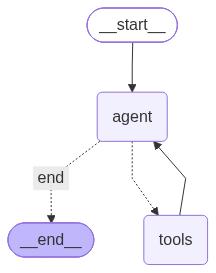

In [47]:
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode
from IPython.display import Image, display

# Create workflow
workflow = StateGraph(SimpleAgentState)

# Create tool node with logging
original_tool_node = ToolNode(tools)

def tool_node_with_logging(state):
    """
    Executes tools and logs their execution.
    """

    logger.info("TOOL NODE: Executing tools...")

    result = original_tool_node.invoke(state)

    logger.info("Tools executed successfully")

    return result


# Add nodes to graph
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)

# Set entry point
workflow.set_entry_point("agent")


# Add conditional edge from agent
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)

# Add edge from tools back to agent
workflow.add_edge("tools", "agent")


# Compile workflow
graph = workflow.compile()

logger.info("✅ Enhanced Gemini agent created successfully\n")

# Display workflow graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
from langchain_core.messages import HumanMessage
from IPython.display import display, Markdown

print("=" * 80)
print("TEST 5: Enhanced Agent with RAG - Ethics and IT Research Check")
print("=" * 80 + "\n")

# Test query that requires information from the ethics PDF
query = (
    "Provide a comprehensive analysis of the ethical issues "
    "in artificial intelligence based on the course document. "
    "Explain the PAPA framework, ACM/IEEE ethical principles, "
    "and the EU AI ethics framework. "
    "Include examples related to privacy, algorithmic bias, "
    "fairness, transparency, and accountability."
)

print(f"Query: {query}\n")
print("-" * 80 + "\n")

# Execute the graph
result = graph.invoke(
    {"messages": [HumanMessage(content=query)]}
)

# Display the agent response
print("\n🤖 ENHANCED AGENT RESPONSE (with RAG):")
print("=" * 80)

display(Markdown(result["messages"][-1].content))

print("\n" + "=" * 80)

print("\n✅ Notice: The agent now includes:")
print(" • Ethical concepts from the course document")
print(" • AI ethical issues and real-world examples")
print(" • PAPA framework analysis")
print(" • ACM/IEEE ethical principles")
print(" • EU AI ethics framework")
print(" • Integration of information retrieved from the PDF")

15:17:03 [INFO] AGENT NODE: Processing request...
15:17:03 [INFO] Calling Gemini with tools...


TEST 5: Enhanced Agent with RAG - Ethics and IT Research Check

Query: Provide a comprehensive analysis of the ethical issues in artificial intelligence based on the course document. Explain the PAPA framework, ACM/IEEE ethical principles, and the EU AI ethics framework. Include examples related to privacy, algorithmic bias, fairness, transparency, and accountability.

--------------------------------------------------------------------------------



15:17:08 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.8-flash:generateContent "HTTP/1.1 503 Service Unavailable"
15:17:08 [INFO] Retrying google.genai._api_client.BaseApiClient._request_once in 1.58 seconds as it raised ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}.
15:17:24 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.8-flash:generateContent "HTTP/1.1 503 Service Unavailable"
15:17:26 [INFO] Retrying google.genai._api_client.BaseApiClient._request_once in 2.37 seconds as it raised ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}.
15:17:29 [INFO] HTTP Request: POST https://generat